In [1]:
# chargement des librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [2]:
# chargement de quelques modules de machine learning
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score,recall_score
from sklearn.model_selection import cross_val_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import make_column_transformer, ColumnTransformer
from imblearn.over_sampling import SMOTE
from mlxtend.plotting import plot_confusion_matrix
from joblib import dump, load
import pickle
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.svm import SVC

In [3]:
# function to read and return the datasets of features and target
def read_and_prepare_data(input_path):
    # read the dataset
    df = pd.read_csv(input_path)

    # extract dataset of the feature variables
    features = df.drop(['raintomorrow'], axis=1, inplace=False)
    
    # extract the datset of the target variable
    target = df['raintomorrow']

    # transform the target data to numercical data
    target.replace({'No':0, 'Yes': 1}, inplace = True)
    
    return features, target

In [4]:
# chargement du dataset traité pour l'apprentissage automatique
#input_path = '../../datasets/processed/may2022-may2023/processed-weather-aus-may2022-may2023.csv'
#input_path = '../../datasets/processed/dec2008-june2017/processed-weather-aus-dec2008-june2017.csv'
input_path = '../../datasets/processed/dec2008-march2023/processed-weather-aus-2008-2023.csv'
#input_path = '../../datasets/processed/dec2008-may2023/processed-weather-aus-dec2008-may2023.csv'
X, y = read_and_prepare_data(input_path = input_path)

In [5]:
# affichage du dataset des features
X
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220094 entries, 0 to 220093
Data columns (total 24 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   location       220094 non-null  object 
 1   mintemp        218938 non-null  float64
 2   maxtemp        219339 non-null  float64
 3   rainfall       217984 non-null  float64
 4   evaporation    102106 non-null  float64
 5   sunshine       92872 non-null   float64
 6   windgustdir    205050 non-null  object 
 7   windgustspeed  205155 non-null  float64
 8   winddir9am     203539 non-null  object 
 9   winddir3pm     211194 non-null  object 
 10  windspeed9am   216385 non-null  float64
 11  windspeed3pm   212679 non-null  float64
 12  humidity9am    217488 non-null  float64
 13  humidity3pm    213297 non-null  float64
 14  pressure9am    196464 non-null  float64
 15  pressure3pm    196470 non-null  float64
 16  cloud9am       126132 non-null  float64
 17  cloud3pm       120538 non-nul

In [6]:
# affichage du dataset de réponse
y

0         0
1         0
2         0
3         0
4         0
         ..
220089    0
220090    0
220091    0
220092    0
220093    0
Name: raintomorrow, Length: 220094, dtype: int64

In [7]:
# extraction des variables numériques des prédicteurs d'entrainement
num_cols = X.select_dtypes(include = ["int", "float"]).columns
num_cols

Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9am', 'cloud3pm',
       'temp9am', 'temp3pm', 'year', 'month', 'day'],
      dtype='object')

In [8]:
# extraction des variables catégorielles des prédicteurs d'entrainement
cat_cols = X.select_dtypes(exclude = "number").columns
cat_cols

Index(['location', 'windgustdir', 'winddir9am', 'winddir3pm', 'raintoday'], dtype='object')

In [9]:
# function to build the full machine learning pipeline
def build_full_ml_pipeline(ml_estimator,
                   num_vars = num_cols, 
                   cat_vars = cat_cols,
                   impute_num = SimpleImputer(strategy="median"), 
                   impute_var = SimpleImputer(strategy="most_frequent"), 
                   scaler_num = StandardScaler(),
                   encoder_cat = OneHotEncoder()):
  # pipeline to transform numerical variables
  numeric_transformer = make_pipeline(
    (impute_num), 
    (scaler_num)
    )
  
  # pipeline to transform categorical variables
  categorical_transformer = make_pipeline(
    (impute_var),
    (encoder_cat)
    )
  
  # combination of feature transformation pipelines
  preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_vars),
        ('cat', categorical_transformer, cat_vars)
    ]
    )
  
  # incorporat the machine learning estimator to the pipeline
  model = Pipeline(steps=[('preprocessing', preprocessor), 
                        ('regressor', ml_estimator)])
  
  return model

In [10]:
# Nearest Neighbors: Pipeline
pipe_knn = build_full_ml_pipeline(ml_estimator = KNeighborsClassifier(n_neighbors=101, weights='distance', algorithm= 'brute', n_jobs=-1))
# visualisation du pipeline
pipe_knn

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9a...
       'temp9am', 'temp3pm', 'year', 'month', 'day'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder())]),
                                                  Index(['location', 'windgustdir', 'winddir9am', 'winddir3pm', 'raintoday'], dtype='object'))])),
                ('regressor',
                 KNeighborsClassifier(algorithm='brute', n_jobs=-1,
                                      n_neighbors=101, weights='distance'))])

In [11]:
rate = y.value_counts()[0]/y.value_counts()[1]
rate

3.498232132273294

In [12]:
weight = y.value_counts()[0]/(y.value_counts()[0] + y.value_counts()[1])
weight

0.7776904413568748

In [13]:
# Support Vector Machine: Pipeline
pipe_svm = build_full_ml_pipeline(ml_estimator = SVC(random_state=None, kernel='rbf', class_weight={0:(1-weight), 1:weight}))
# visualisation du pipeline
pipe_svm

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9a...3pm',
       'temp9am', 'temp3pm', 'year', 'month', 'day'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder())]),
                                                  Index(['location', 'windgustdir', 'winddir9am', 'winddir3pm', 'raintoday'], dtype='object'))])),
                ('regressor',
                 SVC(class_weight={0: 0.22230955864312518,
                                   1: 0.7776904413568748}))])

In [14]:
# Random Forest: Pipeline
pipe_rf = build_full_ml_pipeline(ml_estimator = RandomForestClassifier(random_state=None, n_estimators=100, class_weight='balanced', n_jobs = -1))
# visualisation du pipeline
pipe_rf




Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9a...cloud3pm',
       'temp9am', 'temp3pm', 'year', 'month', 'day'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder())]),
                                                  Index(['location', 'windgustdir', 'winddir9am', 'winddir3pm', 'raintoday'], dtype='object'))])),
                ('regressor',
                 RandomForestClassifier(class_weight='balanced', n_jobs=-1))])

In [15]:
# Logistic Regression: Pipeline
pipe_lr = build_full_ml_pipeline(ml_estimator = LogisticRegression(random_state=None, max_iter=200, class_weight='balanced', n_jobs=-1))
# visualisation du pipeline
pipe_lr

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9a...,
       'temp9am', 'temp3pm', 'year', 'month', 'day'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder())]),
                                                  Index(['location', 'windgustdir', 'winddir9am', 'winddir3pm', 'raintoday'], dtype='object'))])),
                ('regressor',
                 LogisticRegression(class_weight='balanced', max_iter=200,
                                    n_jobs=-1))])

In [16]:
# XGBoost: Pipeline
pipe_xgb = build_full_ml_pipeline(ml_estimator = XGBClassifier(random_state=None, scale_pos_weight = rate, n_estimators=100, n_jobs=-1))
# visualisation du pipeline
pipe_xgb

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9a...
                               feature_types=None, gamma=None, gpu_id=None,
                               grow_policy=None, importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, n_estimators=100,
                               n_jobs=-1, num_parallel_tree=None,
                               predictor=None, random_state=None, ...))])

In [17]:
# function to compute a machine learning classifier accuracy score
def compute_accuracy_score(model, X, y):
    # create training and test datasets
    X_train, X_test, y_train, y_test = train_test_split(X, y, stratify = y, test_size = 0.3, random_state=57)
    # estimte the provided model pipeline on the training datasets
    model.fit(X_train, y_train)

    # evaluate the estimated model on the test datasets
    predictions = model.predict(X_test)
    model_score = accuracy_score(y_test, predictions)

    return model_score

In [18]:
# evaluation of the nearest neighbors
#score_knn = compute_accuracy_score(model = pipe_knn, X = X, y = y)
#score_knn

In [19]:
# evaluation of the support vector machine
#score_svm = compute_accuracy_score(model = pipe_svm, X = X, y = y)
#score_svm

In [20]:
# evaluation of the random forest
score_rf = compute_accuracy_score(model = pipe_rf, X = X, y = y)
score_rf

0.856623604779718

In [21]:
# evaluation of the logistic regression
score_lr = compute_accuracy_score(model = pipe_lr, X = X, y = y)
score_lr

0.7930303351557649

In [22]:
# evaluation of the extreme gradient boosting
score_xgb = compute_accuracy_score(model = pipe_xgb, X = X, y = y)
score_xgb

0.8197458692392736

In [23]:
# create training and test datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify = y, test_size = 0.3, random_state=57)

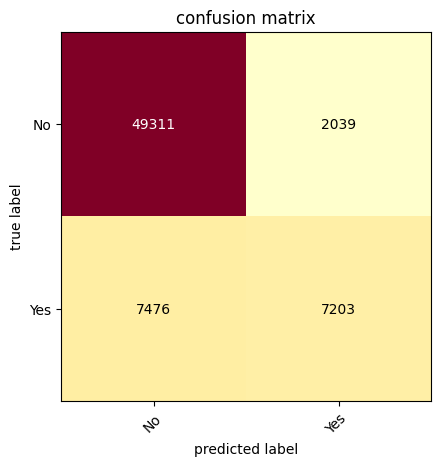

              precision    recall  f1-score   support

           0       0.87      0.96      0.91     51350
           1       0.78      0.49      0.60     14679

    accuracy                           0.86     66029
   macro avg       0.82      0.73      0.76     66029
weighted avg       0.85      0.86      0.84     66029



In [26]:
# Random Forest: Estimation
pipe_rf.fit(X_train,y_train)
predictions = pipe_rf.predict(X_test)
cm=confusion_matrix(y_test, predictions)
plot_confusion_matrix(cm, class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
scores_rf = classification_report(y_test, predictions)
accuracy_rf = accuracy_score(y_test, predictions)
recall_rf = recall_score(y_test, predictions)
precision_rf = precision_score(y_test, predictions)
print(scores_rf)

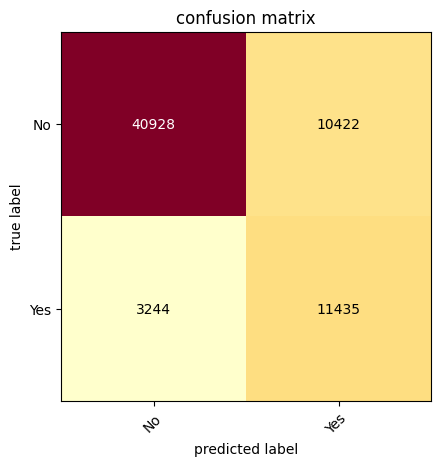

              precision    recall  f1-score   support

           0       0.93      0.80      0.86     51350
           1       0.52      0.78      0.63     14679

    accuracy                           0.79     66029
   macro avg       0.72      0.79      0.74     66029
weighted avg       0.84      0.79      0.81     66029



In [24]:
# Logistic Regression: Estimation
pipe_lr.fit(X_train,y_train)
predictions = pipe_lr.predict(X_test)
cm=confusion_matrix(y_test, predictions)
plot_confusion_matrix(cm, class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
scores_lr = classification_report(y_test, predictions)
accuracy_lr = accuracy_score(y_test, predictions)
recall_lr = recall_score(y_test, predictions)
precision_lr = precision_score(y_test, predictions)
print(scores_lr)

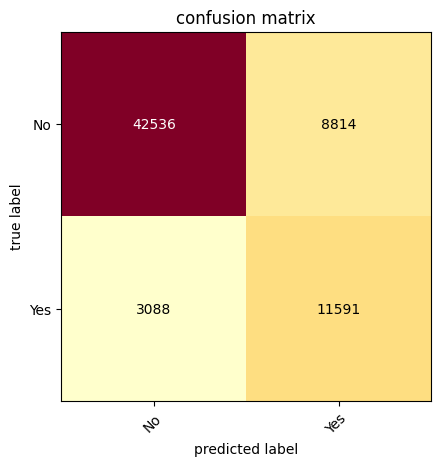

              precision    recall  f1-score   support

           0       0.93      0.83      0.88     51350
           1       0.57      0.79      0.66     14679

    accuracy                           0.82     66029
   macro avg       0.75      0.81      0.77     66029
weighted avg       0.85      0.82      0.83     66029



In [25]:
# XGBoost: Estimation
pipe_xgb.fit(X_train,y_train)
predictions = pipe_xgb.predict(X_test)
cm=confusion_matrix(y_test, predictions)
plot_confusion_matrix(cm, class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
scores_xgb = classification_report(y_test, predictions)
accuracy_xgb = accuracy_score(y_test, predictions)
recall_xgb = recall_score(y_test, predictions)
precision_xgb = precision_score(y_test, predictions)
print(scores_xgb)

In [23]:
# entrainement des deux modèles sur le dataset entier

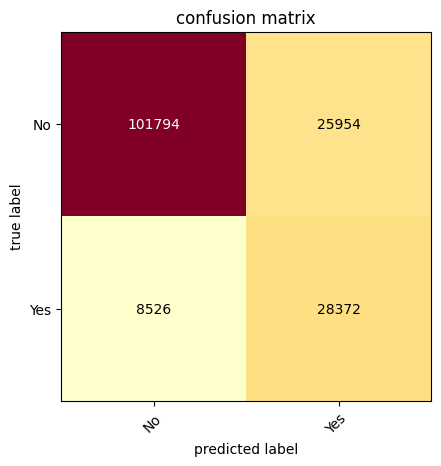

              precision    recall  f1-score   support

           0       0.92      0.80      0.86    127748
           1       0.52      0.77      0.62     36898

    accuracy                           0.79    164646
   macro avg       0.72      0.78      0.74    164646
weighted avg       0.83      0.79      0.80    164646



In [24]:
# Logistic Regression: Estimation
pipe_lr.fit(X,y)
predictions = pipe_lr.predict(X)
cm=confusion_matrix(y, predictions)
plot_confusion_matrix(cm, class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
scores_lr = classification_report(y, predictions)
accuracy_lr = accuracy_score(y, predictions)
recall_lr = recall_score(y, predictions)
print(scores_lr)

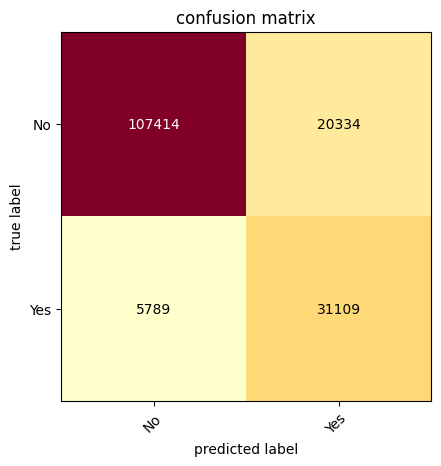

              precision    recall  f1-score   support

           0       0.95      0.84      0.89    127748
           1       0.60      0.84      0.70     36898

    accuracy                           0.84    164646
   macro avg       0.78      0.84      0.80    164646
weighted avg       0.87      0.84      0.85    164646



In [25]:
# XGBoost: Estimation
pipe_xgb.fit(X,y)
predictions = pipe_xgb.predict(X)
cm=confusion_matrix(y, predictions)
plot_confusion_matrix(cm, class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
scores_xgb = classification_report(y, predictions)
accuracy_xgb = accuracy_score(y, predictions)
recall_xgb = recall_score(y, predictions)
print(scores_xgb)

In [26]:
# function to compute, plot and save the confusion matrix
def compute_and_save_confusion_matrix_plot(y_true, y_pred, ouput_path):
    confusion = confusion_matrix(y_true = y_true, y_pred = y_pred)
    plot_confusion_matrix(confusion, class_names=["No","Yes"], cmap='YlOrRd')
    plt.title('confusion matrix')
    plt.savefig(ouput_path)

In [27]:
# function to compute and save the classification report
def compute_and_save_classification_report(y_true, y_pred, ouput_path):
    report = classification_report(y_true = y_true, y_pred = y_pred, target_names = ["No","Yes"], output_dict = True)
    report_df = pd.DataFrame(report)
    report_df.to_csv(ouput_path,  sep=',', float_format='%.5f')

In [28]:
# function to estimate and save the full machine learning pipeline
def estimate_and_save_ml_model_pipeline(model, X, y, output_path):
    # estimte the provided model pipeline
    model.fit(X, y)
    # save the estimated model pipeline
    print(str(model), 'saved at ', output_path)
    pickle.dump(model, open(output_path, 'wb'))

In [29]:
# estimation et sauvegarde du modèle de regression logistique
output_path = '../../models/final-model-pipe-lr' + datetime.now().strftime('-%Y-%m-%d-%H-%M-%S') + '.pkl'
estimate_and_save_ml_model_pipeline(pipe_lr, X, y, output_path)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9a...,
       'temp9am', 'temp3pm', 'year', 'month', 'day'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImpu

In [30]:
# estimation et sauvegarde du modèle de gradient boosting
output_path = '../../models/final-model-pipe-xgb' + datetime.now().strftime('-%Y-%m-%d-%H-%M-%S') + '.pkl'
estimate_and_save_ml_model_pipeline(pipe_xgb, X, y, output_path)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9a...
                               feature_types=None, gamma=None, gpu_id=None,
                               grow_policy=None, importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,


In [31]:
# function to load the saved estimated machine learning pipeline
def load_saved_estimated_ml_model_pipeline(input_path):
    # load the saved model pipeline
    pickled_model = pickle.load(open(input_path, 'rb'))
    return pickled_model

In [32]:
# chargement et utilisation du modèle sauvegardé
input_path = '../../models/final-model-pipe-xgb-2023-07-04-10-06-53.pkl'
pickled_model = load_saved_estimated_ml_model_pipeline(input_path)
# utilisation du modèle chargé
predictions = pickled_model.predict(X_test)
# view the scores
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.95      0.84      0.89     38325
           1       0.61      0.84      0.70     11069

    accuracy                           0.84     49394
   macro avg       0.78      0.84      0.80     49394
weighted avg       0.87      0.84      0.85     49394



In [33]:
# liste de toutes les variables prédictives
X.columns

Index(['location', 'mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustdir', 'windgustspeed', 'winddir9am', 'winddir3pm',
       'windspeed9am', 'windspeed3pm', 'humidity9am', 'humidity3pm',
       'pressure9am', 'pressure3pm', 'cloud9am', 'cloud3pm', 'temp9am',
       'temp3pm', 'raintoday', 'year', 'month', 'day'],
      dtype='object')

In [34]:
# liste des variables numériques
num_cols

Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9am', 'cloud3pm',
       'temp9am', 'temp3pm', 'year', 'month', 'day'],
      dtype='object')

In [35]:
# liste des variables catégorielles
cat_cols

Index(['location', 'windgustdir', 'winddir9am', 'winddir3pm', 'raintoday'], dtype='object')

In [36]:
# modalités de la variable catégorielle: location
X['location'].unique()

array(['Albury', 'BadgerysCreek', 'Cobar', 'CoffsHarbour', 'Moree',
       'Newcastle', 'NorahHead', 'NorfolkIsland', 'Penrith', 'Richmond',
       'Sydney', 'SydneyAirport', 'WaggaWagga', 'Williamtown',
       'Wollongong', 'Canberra', 'Tuggeranong', 'MountGinini', 'Ballarat',
       'Bendigo', 'Sale', 'MelbourneAirport', 'Melbourne', 'Mildura',
       'Nhil', 'Portland', 'Watsonia', 'Dartmoor', 'Brisbane', 'Cairns',
       'GoldCoast', 'Townsville', 'Adelaide', 'MountGambier', 'Nuriootpa',
       'Woomera', 'Albany', 'Witchcliffe', 'PearceRAAF', 'PerthAirport',
       'Perth', 'SalmonGums', 'Walpole', 'Hobart', 'Launceston',
       'AliceSprings', 'Darwin', 'Katherine', 'Uluru'], dtype=object)

In [37]:
# modalités de la variable catégorielle: windgustdir
X['windgustdir'].unique()

array(['W', 'WNW', 'WSW', 'NE', 'NNW', 'N', 'NNE', 'SW', nan, 'ENE',
       'SSE', 'S', 'NW', 'SE', 'ESE', 'E', 'SSW'], dtype=object)

In [38]:
# modalités de la variable catégorielle: winddir9am
X['winddir9am'].unique()

array(['W', 'NNW', 'SE', 'ENE', 'SW', 'SSE', 'S', 'NE', nan, 'SSW', 'N',
       'WSW', 'ESE', 'E', 'NW', 'WNW', 'NNE', ' '], dtype=object)

In [39]:
# modalités de la variable catégorielle: winddir3pm
X['winddir3pm'].unique()

array(['WNW', 'WSW', 'E', 'NW', 'W', 'SSE', 'ESE', 'ENE', 'NNW', 'SSW',
       'SW', 'SE', 'N', 'S', 'NNE', nan, 'NE', ' '], dtype=object)

In [40]:
# modalités de la variable catégorielle: raintoday
X['raintoday'].unique()

array(['No', 'Yes', nan], dtype=object)